In [38]:
import pandas as pd
import string
import nltk

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score
)

In [13]:
data = {
    'category': [
        'sport', 'sport', 'sport', 'sport', 'sport',
        'politics', 'politics', None, 'politics', 'politics',
        'business', 'business', 'business', 'business', 'business',
        'tech', 'tech', 'tech', 'tech', 'tech',
        'entertainment', 'entertainment', 'entertainment',
        'entertainment', 'entertainment'
    ],

    'text': [
        'The football team won the match!',
        'A GREAT victory for the cricket team.',
        'The players are training hard for the tournament.',
        'The coach said that the team played very well.',
        'Football fans celebrated the amazing win!',

        'The government announced a new policy today.',
        'The Prime Minister spoke about the economy.',
        'The election results were announced yesterday!',
        'The parliament discussed the new law.',
        'The government announced a new policy today.',

        'The company reported a significant increase in profits.',
        'Stock markets are rising after the announcement!',
        None,
        'The business recorded a loss this quarter.',
        'Investors are optimistic about the market.',

        'The company launched a new smartphone today.',
        'Artificial intelligence is changing the world!',
        None,
        'Technology companies are investing in robotics.',
        'The new application is easy to use.',

        'The actor starred in a fantastic new movie.',
        'The film received excellent reviews from critics!',
        'The singer released a new album yesterday.',
        'The audience enjoyed the amazing performance.',
        'The director announced a sequel to the popular film.'
    ]
}





In [14]:
df=pd.DataFrame(data)

In [15]:
df.head()

,category,text
0,sport,The football team won the match!
1,sport,A GREAT victory for the cricket team.
2,sport,The players are training hard for the tournament.
3,sport,The coach said that the team played very well.
4,sport,Football fans celebrated the amazing win!


In [16]:
df.shape

(25, 2)

In [17]:
df.columns

Index(['category', 'text'], dtype='object')

In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   category  24 non-null     object
 1   text      23 non-null     object
dtypes: object(2)
memory usage: 532.0+ bytes


In [19]:
df.isnull().sum()

,0
category,1
text,2


In [20]:
# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows containing missing values
df = df.dropna()

# Check missing values again
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDataset shape:", df.shape)

Missing values before cleaning:
category    1
text        2
dtype: int64

Missing values after cleaning:
category    0
text        0
dtype: int64

Dataset shape: (22, 2)


In [21]:
# Check duplicates
print("Duplicates before cleaning:", df.duplicated().sum())

# Remove duplicates
df = df.drop_duplicates()

# Check duplicates again
print("Duplicates after cleaning:", df.duplicated().sum())

print("Dataset shape:", df.shape)

Duplicates before cleaning: 1
Duplicates after cleaning: 0
Dataset shape: (21, 2)


In [22]:
import string

# Convert text to lowercase
df['text'] = df['text'].str.lower()

# Remove punctuation
table = str.maketrans('', '', string.punctuation)
df['text'] = df['text'].str.translate(table)

# Display the cleaned text
print(df['text'].head(10))

0                       the football team won the match
1                  a great victory for the cricket team
2      the players are training hard for the tournament
3         the coach said that the team played very well
4              football fans celebrated the amazing win
5           the government announced a new policy today
6            the prime minister spoke about the economy
8                  the parliament discussed the new law
10    the company reported a significant increase in...
11      stock markets are rising after the announcement
Name: text, dtype: object


In [23]:
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')

STOPWORDS = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [25]:
df = df.reset_index(drop=True)

In [26]:
for i in range(len(df)):
    words = df.loc[i, 'text'].split()

    cleaned_words = []

    for word in words:
        if word not in STOPWORDS:
            cleaned_words.append(word)

    df.loc[i, 'text'] = ' '.join(cleaned_words)

In [27]:
print(df[['category', 'text']].head(10))

   category                                           text
0     sport                            football team match
1     sport                     great victory cricket team
2     sport               players training hard tournament
3     sport                    coach said team played well
4     sport           football fans celebrated amazing win
5  politics          government announced new policy today
6  politics                   prime minister spoke economy
7  politics                   parliament discussed new law
8  business  company reported significant increase profits
9  business              stock markets rising announcement


In [29]:
tfidf = TfidfVectorizer()

X = tfidf.fit_transform(df['text'])
y = df['category']

In [30]:
print("TF-IDF matrix shape:", X.shape)
print("\nTarget categories:")
print(y.value_counts())

print("\nSample TF-IDF feature names:")
print(tfidf.get_feature_names_out()[:20])

TF-IDF matrix shape: (21, 78)

Target categories:
category
sport            5
entertainment    5
business         4
tech             4
politics         3
Name: count, dtype: int64

Sample TF-IDF feature names:
['actor' 'album' 'amazing' 'announced' 'announcement' 'application'
 'artificial' 'audience' 'business' 'celebrated' 'changing' 'coach'
 'companies' 'company' 'cricket' 'critics' 'director' 'discussed' 'easy'
 'economy']


In [31]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text'],
    df['category'],
    test_size=0.2,
    random_state=42,
    stratify=df['category']
)

In [32]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining category distribution:")
print(y_train.value_counts())

print("\nTesting category distribution:")
print(y_test.value_counts())

Training samples: 16
Testing samples: 5

Training category distribution:
category
sport            4
entertainment    4
tech             3
business         3
politics         2
Name: count, dtype: int64

Testing category distribution:
category
entertainment    1
politics         1
business         1
sport            1
tech             1
Name: count, dtype: int64


In [33]:
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [34]:
print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (16, 61)
Testing data shape: (5, 61)


In [35]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [36]:
y_pred = model.predict(X_test_tfidf)

print("Actual categories:")
print(y_test.values)

print("\nPredicted categories:")
print(y_pred)

Actual categories:
['entertainment' 'politics' 'business' 'sport' 'tech']

Predicted categories:
['entertainment' 'entertainment' 'entertainment' 'entertainment'
 'entertainment']


In [37]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 0.2

Classification Report:

               precision    recall  f1-score   support

     business       0.00      0.00      0.00         1
entertainment       0.20      1.00      0.33         1
     politics       0.00      0.00      0.00         1
        sport       0.00      0.00      0.00         1
         tech       0.00      0.00      0.00         1

     accuracy                           0.20         5
    macro avg       0.04      0.20      0.07         5
 weighted avg       0.04      0.20      0.07         5



In [39]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)


In [40]:
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)


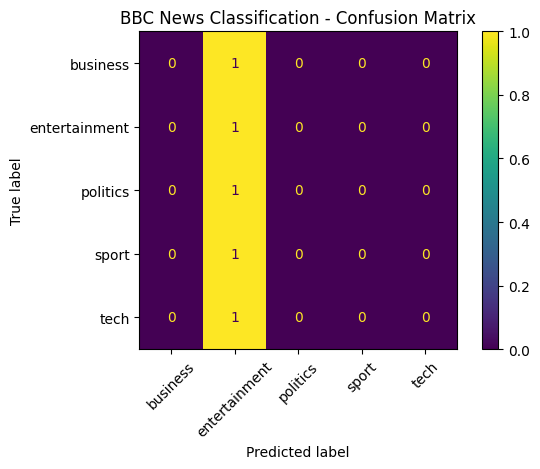

In [41]:
display.plot(xticks_rotation=45)
plt.title("BBC News Classification - Confusion Matrix")
plt.tight_layout()
plt.show()